# Ìmọ́lẹ̀: finding electricity theft from the transformer down
**Probabilistic localisation of electricity theft using transformer phase energy balance and prepaid meter data**

This notebook builds and tests the whole system on a **simulated** Lagos transformer community (a "digital twin"), because no labelled Nigerian theft data is public yet.

**How to run (Google Colab):** Runtime → Run all. It takes about 1 minute. No uploads needed.

**The three layers:**
1. **Transformer phase balance** → which phase, then which street segment, is losing energy (Bayes' rule).
2. **Customer risk ranking** → AI model ranks customers inside the suspicious segment.
3. **Validation** → AI picks the best day and hour, and inspectors confirm with a clamp meter at the service drop before any action.

## Step 1: The simulator (digital twin)
One 11kV/415V three-phase transformer, about 90 prepaid customers on 4 streets, about 15 hours of supply a day, evening peaks. It includes honest customers who look suspicious (solar, vacant houses, running out of units, travel, economising) and five theft types: full bypass, partial bypass, meter tampering, night-only bypass and gradual bypass, plus illegal unmetered connections. `%%writefile` saves the code as a file so the next steps can use it.

In [1]:
%%writefile imole_sim.py
"""Ìmọ́lẹ̀ digital twin: a simulated Lagos distribution-transformer (DT) community.

One 11kV/415V three-phase DT feeds prepaid customers on several streets. Everything
the DisCo could measure is produced (phase meters, optional street "observer" meters,
customer prepaid meters), together with the hidden truth (who steals, how, from when),
so detection can be scored honestly.

All behaviour is SIMULATED. Patterns are chosen to resemble Lagos conditions
(about 15 hours of supply a day, evening peaks, prepaid metering, solar adoption).
"""
import numpy as np

HOD_SHAPE = np.array([0.45, 0.4, 0.38, 0.38, 0.42, 0.6, 0.9, 1.0, 0.85, 0.7, 0.65, 0.65,
                      0.7, 0.7, 0.7, 0.75, 0.85, 1.05, 1.4, 1.6, 1.6, 1.45, 1.1, 0.7])
HOD_SHAPE = HOD_SHAPE / HOD_SHAPE.mean()

THEFT_TYPES = ['full_bypass', 'partial_bypass', 'meter_tamper', 'night_bypass', 'gradual_bypass']


def simulate_dt(seed, n_cust=90, n_streets=4, days=60, theft_rate=0.08, p_illegal=0.5,
                p_solar=0.10, p_vacant=0.04, p_long_term=0.25):
    rng = np.random.default_rng(seed)
    H = days * 24
    hod = np.tile(np.arange(24), days)
    day = np.repeat(np.arange(days), 24)
    weekend = np.isin(day % 7, [5, 6])

    phase = rng.integers(0, 3, n_cust)
    street = rng.integers(0, n_streets, n_cust)

    # Grid supply: on/off Markov chain, about 15-16 hours of supply per day on average
    supply = np.zeros(H, bool); on = True
    for t in range(H):
        on = (rng.random() > 0.08) if on else (rng.random() < 0.15)
        supply[t] = on

    # True household demand (kW) when supply is on
    scale = rng.lognormal(np.log(0.5), 0.5, n_cust)
    personal = np.clip(1 + rng.normal(0, 0.25, (n_cust, 24)), 0.3, None)
    shape = HOD_SHAPE[None, :] * personal
    shape = shape / shape.mean(1, keepdims=True)
    noise = rng.gamma(10, 0.1, (n_cust, H))                    # hour-to-hour variation (cv ~0.3)
    demand = scale[:, None] * shape[:, hod] * noise * np.where(weekend, 1.1, 1.0)

    # Honest behaviour changes that LOOK suspicious (false-flag traps)
    role = np.array(['normal'] * n_cust, dtype=object)
    change_day = np.full(n_cust, -1)
    idx = rng.permutation(n_cust)
    n_thief = max(1, rng.binomial(n_cust, theft_rate)) if theft_rate > 0 else 0
    thieves = idx[:n_thief]
    n_solar = rng.binomial(n_cust, p_solar); solar = idx[n_thief:n_thief + n_solar]
    n_vac = rng.binomial(n_cust, p_vacant); vacant = idx[n_thief + n_solar:n_thief + n_solar + n_vac]
    for i in solar:
        role[i] = 'solar'; d0 = rng.integers(10, 45); change_day[i] = d0
        m = (day >= d0) & (hod >= 9) & (hod <= 16)
        demand[i, m] *= 0.25
    for i in vacant:
        role[i] = 'vacant'; d0 = rng.integers(10, 45); change_day[i] = d0
        demand[i, day >= d0] *= 0.05
    # Everyday honest noise seen on real prepaid meters
    for i in range(n_cust):
        if rng.random() < 0.30:   # ran out of units: dark for a few days, then recharge
            for _ in range(rng.integers(1, 4)):
                d0 = rng.integers(0, days); demand[i, (day >= d0) & (day < d0 + rng.integers(1, 5))] = 0
        if rng.random() < 0.10:   # travel
            d0 = rng.integers(5, days); demand[i, (day >= d0) & (day < d0 + rng.integers(5, 15))] *= 0.05
        if rng.random() < 0.15 and role[i] == 'normal':  # lifestyle / economising / new tenant
            role[i] = 'lifestyle_change'; d0 = rng.integers(10, 45); change_day[i] = d0
            demand[i, day >= d0] *= rng.uniform(0.4, 0.8) if rng.random() < 0.7 else rng.uniform(1.2, 1.6)

    # Theft: share of true demand that the prepaid meter registers
    reg = np.ones((n_cust, H))
    theft_type = np.array([''] * n_cust, dtype=object)
    for i in thieves:
        typ = THEFT_TYPES[rng.integers(len(THEFT_TYPES))]
        theft_type[i] = typ; role[i] = 'thief'
        d0 = 0 if rng.random() < p_long_term else rng.integers(10, 45)
        change_day[i] = d0
        act = day >= d0
        if typ == 'full_bypass':
            reg[i, act] = 0.03
        elif typ == 'partial_bypass':
            reg[i, act] = rng.uniform(0.3, 0.6)          # e.g. AC circuit bypassed
        elif typ == 'meter_tamper':
            reg[i, act] = rng.uniform(0.4, 0.6)          # meter under-registers
        elif typ == 'night_bypass':
            reg[i, act & ((hod >= 22) | (hod < 6))] = 0.0  # steals only at night
        elif typ == 'gradual_bypass':                    # slowly increases theft to avoid sudden drop
            ramp = np.clip((day - d0) / 25, 0, 1)
            reg[i, act] = 1 - 0.7 * ramp[act]

    # Illegal unmetered connections (no meter at all)
    illegal = []
    if rng.random() < p_illegal:
        for _ in range(rng.integers(1, 3)):
            ph, st, d0 = rng.integers(0, 3), rng.integers(0, n_streets), rng.integers(0, 45)
            load = rng.lognormal(np.log(0.6), 0.4) * HOD_SHAPE[hod] * rng.gamma(10, 0.1, H) * (day >= d0)
            illegal.append(dict(phase=ph, street=st, start=d0, load=load))

    true = demand * supply[None, :]
    meter_bias = 1 + rng.normal(0, 0.01, n_cust)
    metered = true * reg * meter_bias[:, None]
    missing = rng.random((n_cust, H)) < 0.01
    metered_obs = np.where(missing, np.nan, metered)

    # Phase and street-segment energy (true flow incl. illegal), with technical losses
    def seg_flow(mask_c, ph, st=None):
        f = true[mask_c].sum(0)
        for il in illegal:
            if il['phase'] == ph and (st is None or il['street'] == st):
                f = f + il['load'] * supply
        return f
    phase_load = np.array([seg_flow(phase == p, p) for p in range(3)])
    c = 0.04 / max(phase_load[phase_load > 0].mean(), 1e-6)    # ~4% average technical loss
    tech = c * phase_load ** 2
    pm_bias = 1 + rng.normal(0, 0.005, 3)
    phase_meter = (phase_load + tech) * pm_bias[:, None] * (1 + rng.normal(0, 0.002, (3, H)))
    street_meter = np.zeros((n_streets, 3, H))
    for s in range(n_streets):
        for p in range(3):
            fl = seg_flow((phase == p) & (street == s), p, s)
            street_meter[s, p] = (fl + c * fl * phase_load[p]) * (1 + rng.normal(0, 0.003))

    return dict(H=H, days=days, hod=hod, day=day, supply=supply, phase=phase, street=street,
                n_streets=n_streets, metered=metered_obs, phase_meter=phase_meter,
                street_meter=street_meter, tech_coef_true=c,
                truth=dict(role=role, theft_type=theft_type, change_day=change_day, illegal=illegal,
                           reg=reg, true=true))


Writing imole_sim.py


## Step 2: The detector
- `segment_probability`: Bayes' rule. *If there were no theft, the unexplained loss would sit near 0% (meter and loss-estimate error). How likely is the loss we see under theft vs no theft?*
- `analyse_dt`: computes phase and street gaps, then features for each customer (drops by time of day, solar signature, low vs neighbours, how well their missing usage matches the gap).
- `plan_inspection`: picks a high-gap day (randomly among the top 3) and the best 2-hour window.
- `field_check`: simulates the inspector's clamp-meter check at the service drop.

In [2]:
%%writefile imole_detect.py
"""Ìmọ́lẹ̀ detection: transformer phase balance -> street segment -> customer ranking,
plus an inspection-day planner and a simulated field spot-check."""
import numpy as np
from scipy.stats import norm

BASE_DAYS = 7      # first week used as each customer's own baseline
RECENT_DAYS = 14   # recent window for decisions


def _fill(metered, hod, supply):
    """Fill missing prepaid readings with the customer's own average for that hour."""
    m = metered.copy()
    for h in range(24):
        cols = (hod == h) & supply
        mean_h = np.nanmean(np.where(cols[None, :], m, np.nan), axis=1)
        nan = np.isnan(m) & (hod == h)[None, :]
        m[nan] = np.broadcast_to(mean_h[:, None], m.shape)[nan]
    return np.nan_to_num(m * supply[None, :])


def segment_probability(ntl_share, sigma0=0.012, prior=0.3, max_theft=0.6):
    """Bayes: P(theft | observed non-technical loss share) for a phase or street segment.
    Without theft the share ~ Normal(0, sigma0) (meter + loss-estimate error).
    With theft it is anywhere between 0 and max_theft."""
    l0 = norm.pdf(ntl_share, 0, sigma0)
    l1 = np.where((ntl_share > 0) & (ntl_share < max_theft), 1 / max_theft, 1e-9)
    return prior * l1 / (prior * l1 + (1 - prior) * l0)


def analyse_dt(dt, analysis_days=60, tech_err=0.2, rng=None):
    rng = rng or np.random.default_rng(0)
    T = analysis_days * 24
    hod, day, supply = dt['hod'][:T], dt['day'][:T], dt['supply'][:T]
    M = _fill(dt['metered'][:, :T], hod, supply)
    n = M.shape[0]
    phase, street, S = dt['phase'], dt['street'], dt['n_streets']
    c_hat = dt['tech_coef_true'] * (1 + rng.normal(0, tech_err))   # engineering estimate of losses
    base = day < BASE_DAYS
    recent = day >= analysis_days - RECENT_DAYS

    # --- Layer 1: phase and street-segment gaps -------------------------------------
    PM = dt['phase_meter'][:, :T]
    phase_gap = PM - np.array([M[phase == p].sum(0) for p in range(3)]) - c_hat * PM ** 2
    phase_share = phase_gap[:, recent].sum(1) / np.maximum(PM[:, recent].sum(1), 1e-9)
    SM = dt['street_meter'][:, :, :T]
    seg_gap = np.zeros_like(SM)
    for s in range(S):
        for p in range(3):
            mask = (phase == p) & (street == s)
            seg_gap[s, p] = SM[s, p] - M[mask].sum(0) - c_hat * SM[s, p] * PM[p]
    seg_share = seg_gap[:, :, recent].sum(2) / np.maximum(SM[:, :, recent].sum(2), 1e-9)
    phase_prob = segment_probability(phase_share)
    seg_prob = segment_probability(seg_share)

    # --- Layer 2: customer features -------------------------------------------------
    on_b, on_r = base & supply, recent & supply
    b0 = M[:, on_b].mean(1) + 1e-6
    b1 = M[:, on_r].mean(1)
    prof = np.stack([M[:, on_b & (hod == h)].mean(1) for h in range(24)], 1) + 1e-6
    def part(hours):
        hm = np.isin(hod, hours)
        return 1 - M[:, on_r & hm].mean(1) / (M[:, on_b & hm].mean(1) + 1e-6)
    night, midday, evening = list(range(22, 24)) + list(range(0, 6)), list(range(9, 17)), list(range(17, 22))
    expected = prof[:, hod] * supply[None, :]
    missing = np.clip(expected - M, 0, None)

    feats = {}
    feats['drop_overall'] = np.clip(1 - b1 / b0, -2, 1)
    feats['drop_night'] = np.clip(part(night), -2, 1)
    feats['drop_midday'] = np.clip(part(midday), -2, 1)
    feats['drop_evening'] = np.clip(part(evening), -2, 1)
    feats['solar_signature'] = feats['drop_midday'] - feats['drop_evening']
    med_peer = np.array([np.median(b1[phase == phase[i]]) for i in range(n)])
    feats['low_vs_peers'] = np.clip(1 - b1 / (med_peer + 1e-6), -3, 1)
    feats['zero_share_recent'] = (M[:, on_r] < 0.02).mean(1)
    feats['phase_ntl_share'] = phase_share[phase]
    feats['phase_theft_prob'] = phase_prob[phase]
    feats['street_ntl_share'] = seg_share[street, phase]
    feats['street_theft_prob'] = seg_prob[street, phase]
    corr_p, corr_s, explain = np.zeros(n), np.zeros(n), np.zeros(n)
    dmiss = missing.reshape(n, -1, 24).sum(2)
    for i in range(n):
        g_p, g_s = phase_gap[phase[i]], seg_gap[street[i], phase[i]]
        if missing[i].std() > 0:
            corr_p[i] = np.corrcoef(missing[i], g_p)[0, 1]
            corr_s[i] = np.corrcoef(missing[i], g_s)[0, 1]
        gs = g_s.reshape(-1, 24).sum(1)
        explain[i] = np.clip(dmiss[i, -RECENT_DAYS:].sum() / max(gs[-RECENT_DAYS:].sum(), 1e-6), 0, 3)
    # Long-term thieves have no "before": compare their deficit vs neighbours with the segment gap
    seg_gap_kw = np.array([seg_gap[street[i], phase[i]][on_r].mean() for i in range(n)])
    deficit = np.clip(med_peer - b1, 0, None)
    feats['deficit_vs_segment_gap'] = np.clip(deficit / np.maximum(seg_gap_kw, 1e-3), 0, 3) * (seg_gap_kw > 0.05)
    feats['gap_corr_phase'] = np.nan_to_num(corr_p)
    feats['gap_corr_street'] = np.nan_to_num(corr_s)
    feats['share_of_gap_explained'] = explain
    X = np.column_stack(list(feats.values()))
    return dict(X=X, names=list(feats), phase_prob=phase_prob, seg_prob=seg_prob,
                phase_share=phase_share, seg_share=seg_share, phase_gap=phase_gap, seg_gap=seg_gap,
                gap_by_hod=np.array([phase_gap.sum(0)[recent & supply & (hod == h)].mean()
                                     if (recent & supply & (hod == h)).any() else 0 for h in range(24)]))


FEATURE_SETS = {
    'customer_only': ['drop_overall', 'drop_night', 'drop_midday', 'drop_evening', 'solar_signature',
                      'low_vs_peers', 'zero_share_recent'],
}
FEATURE_SETS['plus_phase_balance'] = FEATURE_SETS['customer_only'] + ['phase_ntl_share', 'phase_theft_prob',
                                                                       'gap_corr_phase']
FEATURE_SETS['plus_street_meters'] = FEATURE_SETS['plus_phase_balance'] + ['street_ntl_share', 'street_theft_prob',
                                                                            'gap_corr_street', 'share_of_gap_explained', 'deficit_vs_segment_gap']


def plan_inspection(dt, res, start_day=60, horizon=30, top_n=3, rng=None, forecast_err=2.0,
                    work_hours=range(7, 22)):
    """Pick an inspection day and 2-hour window for the coming month.
    Expected gap on a day = typical stolen kW in each hour x chance supply is on.
    Supply hours are taken from a noisy forecast (dispatch / load-shedding plan)."""
    rng = rng or np.random.default_rng(0)
    sup = dt['supply'].reshape(-1, 24)[start_day:start_day + horizon]
    fc_hours = np.clip(sup.sum(1) + rng.normal(0, forecast_err, len(sup)), 0, 24)
    gap_h = np.clip(res['gap_by_hod'], 0, None)
    exp_gap = fc_hours / 24 * gap_h[list(work_hours)].sum()
    best_days = np.argsort(-exp_gap)[:top_n]
    d = int(rng.choice(best_days))                        # random among the best: harder to predict
    wh = np.array(list(work_hours))
    win = [gap_h[h] + gap_h[h + 1] for h in wh[:-1]]
    h0 = int(wh[:-1][int(np.argmax(win))])
    return start_day + d, (h0, h0 + 1)


def field_check(dt, cust, day, hours):
    """Inspector clamps the service drop at the pole and compares with the meter for the window.
    Theft is caught if supply is on and the meter is under-registering during the visit."""
    t = [day * 24 + h for h in hours]
    on = dt['supply'][t]
    reg = dt['truth']['reg'][cust, t]
    return bool(np.any(on & (reg < 0.9)))


def monthly_survey_plan(dt, res, cust_scores, month_start, threshold=0.5, max_visits=10, rng=None):
    """ONE survey per month, triggered only by the AI.
    The survey team moves only if at least one street segment has P(theft) above the threshold.
    Returns None (no survey this month) or a plan: day, time window, segments and households to visit.
    cust_scores: risk score per customer from the trained model (higher = more suspicious)."""
    flagged = np.argwhere(res['seg_prob'] > threshold)          # (street, phase) pairs
    if len(flagged) == 0:
        return None
    day, window = plan_inspection(dt, res, start_day=month_start, rng=rng)
    in_flag = np.zeros(len(cust_scores), bool)
    for s, p in flagged:
        in_flag |= (dt['street'] == s) & (dt['phase'] == p)
    cand = np.where(in_flag)[0]
    visit = cand[np.argsort(-cust_scores[cand])][:max_visits]
    names = dict(zip(res['names'], res['X'].T))
    night = names['drop_night'] - np.maximum(names['drop_evening'], names['drop_midday']) > 0.3
    return dict(day=int(day), window=window,
                segments=[dict(street=int(s) + 1, phase='ABC'[p], p_theft=float(res['seg_prob'][s, p])) for s, p in flagged],
                households=[dict(customer=int(i), risk=float(cust_scores[i]),
                                 visit='night operation 22:00-23:00' if night[i] else f'{window[0]}:00-{window[1] + 1}:00')
                            for i in visit])


Writing imole_detect.py


## Step 3: Look inside one transformer
The Gap = what the phase or street meter measured − what the prepaid meters recorded − normal technical loss.

In [3]:
import numpy as np, matplotlib.pyplot as plt
from imole_sim import simulate_dt
from imole_detect import analyse_dt, plan_inspection
dt = simulate_dt(seed=7, days=90)
res = analyse_dt(dt, rng=np.random.default_rng(1))
tr = dt['truth']
print('Thieves (hidden truth):', [(int(i), tr['theft_type'][i], 'phase', 'ABC'[dt['phase'][i]], 'street', int(dt['street'][i]) + 1) for i in np.where(tr['role'] == 'thief')[0]])
print('Illegal connections:', [('phase', 'ABC'[il['phase']], 'street', il['street'] + 1) for il in tr['illegal']])
print('\nPhase loss share (last 14 days):', {('ABC'[p]): f"{100*res['phase_share'][p]:.1f}%" for p in range(3)})
print('P(theft) per phase:', {('ABC'[p]): f"{res['phase_prob'][p]:.2f}" for p in range(3)})
print('\nP(theft) per street segment (rows = street 1-4, columns = phase A B C):')
print(np.round(res['seg_prob'], 2))

Thieves (hidden truth): [(11, 'night_bypass', 'phase', 'C', 'street', 2), (13, 'meter_tamper', 'phase', 'A', 'street', 3), (17, 'partial_bypass', 'phase', 'C', 'street', 2), (28, 'night_bypass', 'phase', 'B', 'street', 2), (31, 'meter_tamper', 'phase', 'B', 'street', 3), (32, 'partial_bypass', 'phase', 'B', 'street', 2), (55, 'partial_bypass', 'phase', 'C', 'street', 4), (56, 'full_bypass', 'phase', 'C', 'street', 1), (58, 'night_bypass', 'phase', 'B', 'street', 3), (66, 'full_bypass', 'phase', 'A', 'street', 4), (76, 'partial_bypass', 'phase', 'B', 'street', 1), (89, 'meter_tamper', 'phase', 'B', 'street', 1)]
Illegal connections: [('phase', 'A', 'street', np.int64(1)), ('phase', 'C', 'street', np.int64(4))]

Phase loss share (last 14 days): {'A': '6.2%', 'B': '10.9%', 'C': '11.2%'}
P(theft) per phase: {'A': '1.00', 'B': '1.00', 'C': '1.00'}

P(theft) per street segment (rows = street 1-4, columns = phase A B C):
[[1. 1. 1.]
 [0. 1. 1.]
 [1. 1. 0.]
 [1. 0. 1.]]


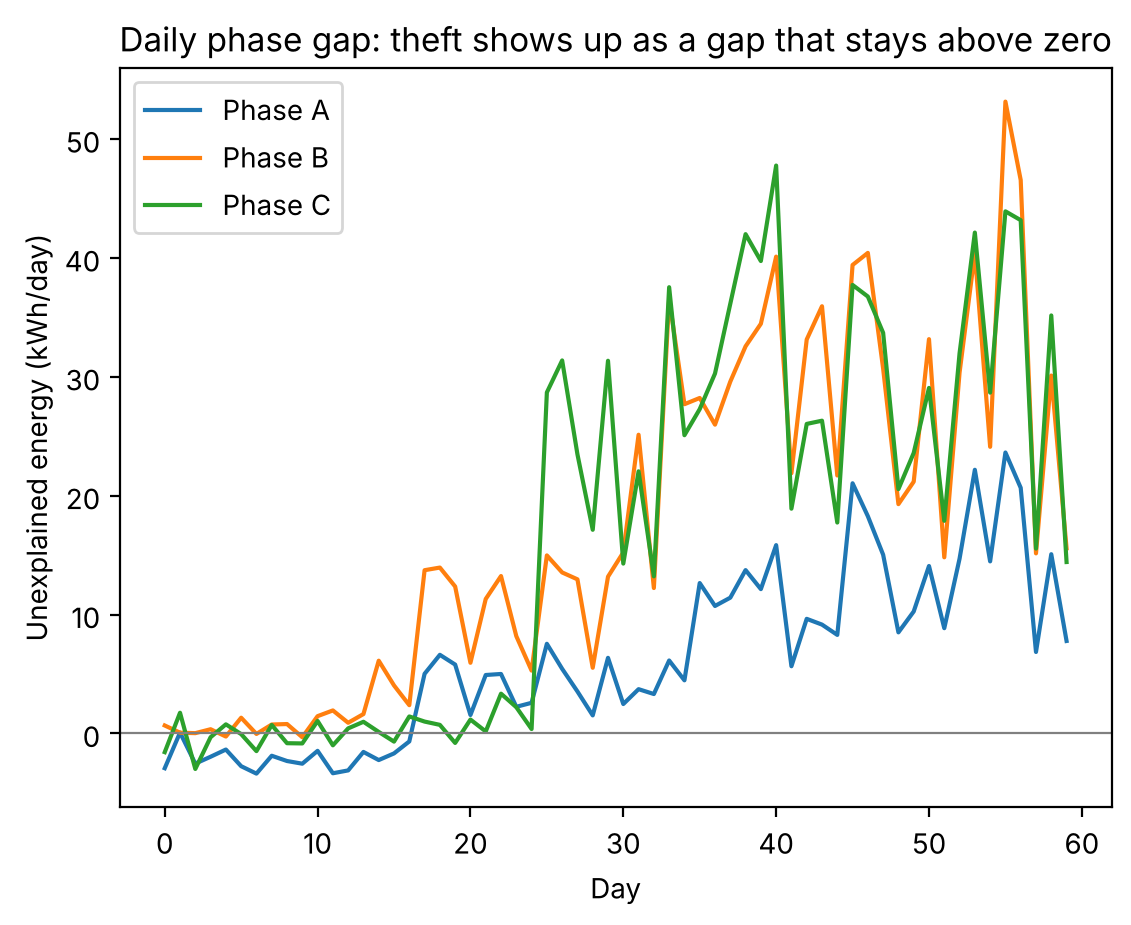

In [4]:
daily = res['phase_gap'].reshape(3, -1, 24).sum(2)
for p in range(3): plt.plot(daily[p], label=f'Phase {"ABC"[p]}')
plt.axhline(0, color='grey', lw=0.8); plt.xlabel('Day'); plt.ylabel('Unexplained energy (kWh/day)')
plt.title('Daily phase gap: theft shows up as a gap that stays above zero'); plt.legend(); plt.show()

## Step 4: Train on 160 transformers, test on 60 new ones
40% of transformers have no theft at all, as in real life. Three versions are compared:
- **customer_only:** prepaid meter data only.
- **plus_phase_balance:** adds transformer phase meters.
- **plus_street_meters:** adds street observer meters.

In [5]:
%%writefile run_experiment.py
"""Train and evaluate Ìmọ́lẹ̀ on simulated transformer communities.
Usage: python run_experiment.py <output dir> [n_train] [n_test]"""
import sys, json, numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
import os; _h = os.path.dirname(os.path.abspath(__file__)); sys.path[:0] = [_h, os.path.join(_h, "..", "src")]
from imole_sim import simulate_dt, THEFT_TYPES
from imole_detect import analyse_dt, FEATURE_SETS, plan_inspection, field_check

out = sys.argv[1]
N_TRAIN = int(sys.argv[2]) if len(sys.argv) > 2 else 160
N_TEST = int(sys.argv[3]) if len(sys.argv) > 3 else 60
K = 5  # inspections per transformer per round

rows, dts, results = [], {}, {}
for seed in range(N_TRAIN + N_TEST):
    clean = seed % 5 in (0, 1)   # 40% of transformers have no theft at all
    dt = simulate_dt(seed, days=90, theft_rate=0 if clean else 0.08, p_illegal=0 if clean else 0.5)
    res = analyse_dt(dt, rng=np.random.default_rng(10_000 + seed))
    tr = dt['truth']
    for i in range(len(dt['phase'])):
        rows.append(dict(dt=seed, clean=int(clean), cust=i, y=int(tr['role'][i] == 'thief'), role=tr['role'][i],
                         ttype=tr['theft_type'][i], long_term=int(tr['role'][i] == 'thief' and tr['change_day'][i] == 0),
                         **dict(zip(res['names'], res['X'][i]))))
    if seed >= N_TRAIN:
        dts[seed], results[seed] = dt, res
df = pd.DataFrame(rows)
train, test = df[df.dt < N_TRAIN], df[df.dt >= N_TRAIN]

summary = dict(n_train_dt=N_TRAIN, n_test_dt=N_TEST, customers_per_dt=90,
               test_customers=int(len(test)), test_thieves=int(test.y.sum()),
               test_solar=int((test.role == 'solar').sum()), test_vacant=int((test.role == 'vacant').sum()))
variant_rows, scores = [], {}
for name, cols in FEATURE_SETS.items():
    m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight='balanced', random_state=1)
    m.fit(train[cols], train.y)
    p = m.predict_proba(test[cols])[:, 1]
    t = test.assign(p=p); scores[name] = t
    found = flagged_honest_low = total_thieves = 0
    for _, g in t.groupby('dt'):
        top = g.nlargest(K, 'p')
        found += top.y.sum(); total_thieves += g.y.sum()
        flagged_honest_low += top.role.isin(['solar', 'vacant']).sum()
    n_dt = t.dt.nunique()
    variant_rows.append(dict(variant=name, auc=roc_auc_score(t.y, p),
                             thieves_found_top5_pct=100 * found / total_thieves,
                             hit_rate_top5_pct=100 * found / (K * n_dt),
                             honest_low_users_flagged_per_100_inspections=100 * flagged_honest_low / (K * n_dt)))
    # Global budget: DisCo inspects the riskiest 3% of ALL customers across all transformers
    nb = int(0.03 * len(t)); top = t.nlargest(nb, 'p')
    variant_rows[-1].update(budget_visits=nb, budget_hit_rate_pct=100 * top.y.mean(),
                            budget_thieves_found_pct=100 * top.y.sum() / t.y.sum(),
                            budget_visits_to_clean_dts_pct=100 * top.clean.mean())
    t.to_csv(f'{out}/pred_{name}.csv', index=False)
var = pd.DataFrame(variant_rows); var.to_csv(f'{out}/variants.csv', index=False)
print(var.round(3).to_string())

# Recall by theft type (best variant), thieves found within top 5 of their transformer
best = scores['plus_street_meters']
best = best.assign(rank=best.groupby('dt').p.rank(ascending=False))
by_type = best[best.y == 1].groupby('ttype').apply(lambda g: pd.Series(dict(n=len(g), found_top5_pct=100 * (g['rank'] <= K).mean())))
by_type.to_csv(f'{out}/by_theft_type.csv'); print(by_type)
lt = best[best.y == 1].groupby('long_term').apply(lambda g: 100 * (g['rank'] <= K).mean())
print('long-term vs new thieves found %', lt.to_dict())
# Honest drops: how often solar / vacant reach top 5 in each variant
for name, t in scores.items():
    t = t.assign(rank=t.groupby('dt').p.rank(ascending=False))
    for r in ['solar', 'vacant']:
        summary[f'{name}_{r}_in_top5_pct'] = float(100 * (t[t.role == r]['rank'] <= K).mean())

# Layer 1: street-segment probability vs truth
seg_true, seg_p, phase_true, phase_p, illegal_hit, illegal_n = [], [], [], [], 0, 0
for s, dt in dts.items():
    res, tr = results[s], dt['truth']
    T0, T1 = (60 - 14) * 24, 60 * 24
    stolen = (tr['true'][:, T0:T1] * (1 - tr['reg'][:, T0:T1])).sum(1)
    for p in range(3):
        st = stolen[dt['phase'] == p].sum() + sum(il['load'][T0:T1].sum() for il in tr['illegal'] if il['phase'] == p)
        phase_true.append(int(st > 0.02 * dt['phase_meter'][p, T0:T1].sum())); phase_p.append(res['phase_prob'][p])
        for sn in range(dt['n_streets']):
            m = (dt['phase'] == p) & (dt['street'] == sn)
            ss = stolen[m].sum() + sum(il['load'][T0:T1].sum() for il in tr['illegal'] if il['phase'] == p and il['street'] == sn)
            seg_true.append(int(ss > 0.02 * dt['street_meter'][sn, p, T0:T1].sum())); seg_p.append(res['seg_prob'][sn, p])
    for il in tr['illegal']:
        if il['start'] < 46:
            illegal_n += 1; illegal_hit += int(res['seg_prob'][il['street'], il['phase']] > 0.5)
seg_true, seg_p, phase_true, phase_p = map(np.array, (seg_true, seg_p, phase_true, phase_p))
summary.update(phase_auc=float(roc_auc_score(phase_true, phase_p)), phase_acc=float(((phase_p > 0.5) == phase_true).mean()),
               segment_auc=float(roc_auc_score(seg_true, seg_p)), segment_acc=float(((seg_p > 0.5) == seg_true).mean()),
               segments_with_theft_pct=float(100 * seg_true.mean()),
               illegal_connections=illegal_n, illegal_segments_flagged_pct=float(100 * illegal_hit / max(illegal_n, 1)))

# Inspection planning: field spot-check on the top-5 flagged thieves, planned vs random timing
rng = np.random.default_rng(99)
plan_hits = rand_hits = n_visits = 0
by_type_visit = {}
for s, dt in dts.items():
    t = best[best.dt == s].nlargest(K, 'p')
    day, hours = plan_inspection(dt, results[s], rng=rng)
    if dt['truth']['role'].tolist().count('thief') == 0: continue
    for _, r in t[t.y == 1].iterrows():
        rd = int(rng.integers(60, 90)); rh = int(rng.integers(8, 17))
        night_sig = r.drop_night - max(r.drop_evening, r.drop_midday) > 0.3
        vis = (22, 23) if night_sig else hours
        ph = field_check(dt, int(r.cust), day, vis); rh_ = field_check(dt, int(r.cust), rd, (rh, rh + 1))
        plan_hits += ph; rand_hits += rh_; n_visits += 1
        d = by_type_visit.setdefault(r.ttype, [0, 0, 0]); d[0] += ph; d[1] += rh_; d[2] += 1
summary.update(field_visits=n_visits, planned_visit_catch_pct=float(100 * plan_hits / n_visits),
               random_visit_catch_pct=float(100 * rand_hits / n_visits),
               visit_by_type={k: dict(planned=100 * v[0] / v[2], random=100 * v[1] / v[2], n=v[2]) for k, v in by_type_visit.items()})
curve = []
for name, t in scores.items():
    o = t.sort_values('p', ascending=False).reset_index(drop=True)
    for pct in [1, 2, 3, 5, 7, 10, 15]:
        k = int(len(o) * pct / 100)
        curve.append(dict(variant=name, inspect_pct=pct, thieves_found_pct=100 * o.y[:k].sum() / o.y.sum()))
pd.DataFrame(curve).to_csv(f'{out}/gains.csv', index=False)
b = scores['plus_street_meters']
flag = b.street_theft_prob > 0.5
summary.update(narrow_customers_in_flagged_segments_pct=float(100 * flag.mean()),
               narrow_thieves_in_flagged_segments_pct=float(100 * b.y[flag].sum() / b.y.sum()),
               narrow_avg_customers_per_flagged_segment=float(b[flag].groupby(['dt', 'street_theft_prob']).size().mean()))
json.dump(summary, open(f'{out}/summary.json', 'w'), indent=1, default=float)
print(json.dumps(summary, indent=1, default=float))


Writing run_experiment.py


In [6]:
!mkdir -p out && python run_experiment.py out 160 60 2>/dev/null | tail -5

 },
 "narrow_customers_in_flagged_segments_pct": 24.90740740740741,
 "narrow_thieves_in_flagged_segments_pct": 85.2,
 "narrow_avg_customers_per_flagged_segment": 11.208333333333334
}


           variant  auc  budget_hit_rate_pct  budget_visits_to_clean_dts_pct
     customer_only 0.96                88.89                            4.32
plus_phase_balance 0.98                91.36                            0.00
plus_street_meters 0.99                95.68                            0.00


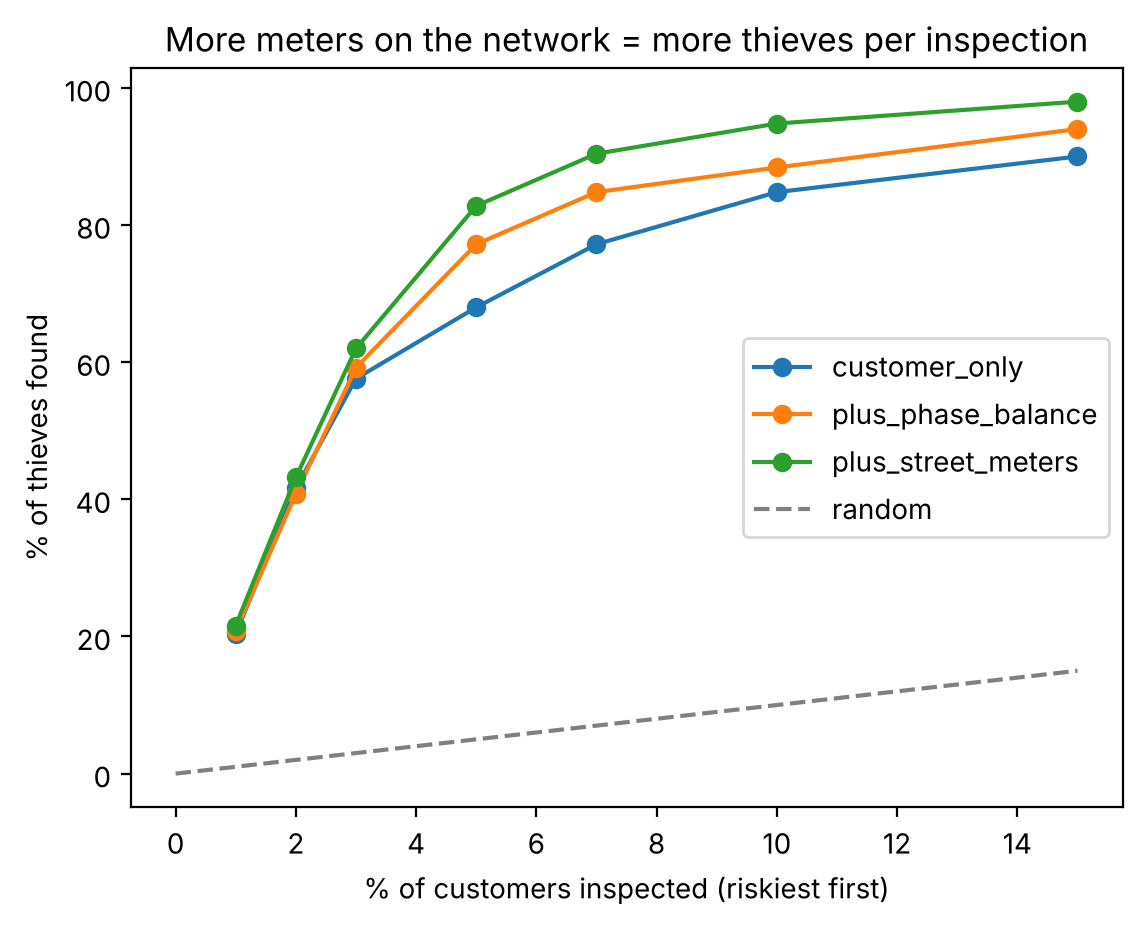

Flagged street segments hold 25% of customers but 85% of thieves
Illegal unmetered connections located to the right street and phase: 100% of 29
Field visits catching theft in progress: planned 99% vs random timing 50%


In [7]:
import pandas as pd, json
pd.set_option('display.width', 200)
v = pd.read_csv('out/variants.csv')
print(v[['variant', 'auc', 'budget_hit_rate_pct', 'budget_visits_to_clean_dts_pct']].round(2).to_string(index=False))
g = pd.read_csv('out/gains.csv').pivot(index='inspect_pct', columns='variant', values='thieves_found_pct')
g.plot(marker='o'); plt.plot([0, 15], [0, 15], '--', color='grey', label='random')
plt.xlabel('% of customers inspected (riskiest first)'); plt.ylabel('% of thieves found'); plt.legend(); plt.title('More meters on the network = more thieves per inspection'); plt.show()
s = json.load(open('out/summary.json'))
print(f"Flagged street segments hold {s['narrow_customers_in_flagged_segments_pct']:.0f}% of customers but {s['narrow_thieves_in_flagged_segments_pct']:.0f}% of thieves")
print(f"Illegal unmetered connections located to the right street and phase: {s['illegal_segments_flagged_pct']:.0f}% of {s['illegal_connections']}")
print(f"Field visits catching theft in progress: planned {s['planned_visit_catch_pct']:.0f}% vs random timing {s['random_visit_catch_pct']:.0f}%")

## Step 5: The monthly survey trigger
**At most one survey a month, and only if the AI flags a street segment.** The AI picks a high-gap day (randomly among the top 3, so thieves cannot predict it) and the best 2-hour window. Households with a night-only pattern get a night operation. A theft-free transformer gets no survey.

In [8]:
from imole_detect import monthly_survey_plan
def plan_for(dt, res):
    score = res['X'][:, res['names'].index('street_theft_prob')] + res['X'][:, res['names'].index('drop_overall')]
    return monthly_survey_plan(dt, res, score, month_start=60, rng=np.random.default_rng(5))
plan = plan_for(dt, res)
print(f"SURVEY THIS MONTH: day {plan['day']}, {plan['window'][0]}:00-{plan['window'][1]+1}:00")
print('Flagged segments:', [(s['street'], s['phase'], round(s['p_theft'], 2)) for s in plan['segments']])
for h in plan['households']: print('  visit household', h['customer'], '->', h['visit'])
clean_dt = simulate_dt(seed=5, days=90, theft_rate=0, p_illegal=0)
print('\nTheft-free transformer:', plan_for(clean_dt, analyse_dt(clean_dt, rng=np.random.default_rng(1))) or 'NO SURVEY this month')

SURVEY THIS MONTH: day 84, 18:00-20:00
Flagged segments: [(1, 'A', 1.0), (1, 'B', 1.0), (1, 'C', 1.0), (2, 'B', 1.0), (2, 'C', 1.0), (3, 'A', 1.0), (3, 'B', 1.0), (4, 'A', 1.0), (4, 'C', 1.0)]
  visit household 56 -> 18:00-20:00
  visit household 66 -> 18:00-20:00
  visit household 62 -> 18:00-20:00
  visit household 74 -> 18:00-20:00
  visit household 67 -> 18:00-20:00
  visit household 45 -> 18:00-20:00
  visit household 87 -> 18:00-20:00
  visit household 63 -> 18:00-20:00
  visit household 52 -> 18:00-20:00
  visit household 76 -> 18:00-20:00

Theft-free transformer: NO SURVEY this month


## Limits (be honest with the judges)
- All results are from **simulated** data shaped to look like Lagos conditions. They show the method works; a pilot transformer is needed to confirm real-world numbers.
- Theft that taps the line **before** the transformer meter, or staff collusion that falsifies readings, cannot be caught by this balance alone.
- Partial bypass and meter tampering look like an honest customer cutting usage. The AI narrows the search to the street; the **field check confirms**.
- A risk score is **never** proof. No disconnection without physical verification and the customer's right to respond.